## Import required libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Train test split
from sklearn.model_selection import train_test_split

# Machine learning algorithms
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor

# Evaluation
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

# Save model
import joblib

import warnings
warnings.filterwarnings('ignore')

## Load the dataset

In [2]:
df = pd.read_csv(r"C:\Users\User\Downloads\Renewable.csv\Renewable.csv")

In [3]:
df.head()

,Time,Energy delta[Wh],GHI,temp,pressure,humidity,wind_speed,rain_1h,snow_1h,clouds_all,isSun,sunlightTime,dayLength,SunlightTime/daylength,weather_type,hour,month
0,2017-01-01 00:00:00,0,0.0,1.6,1021,100,4.9,0.0,0.0,100,0,0,450,0.0,4,0,1
1,2017-01-01 00:15:00,0,0.0,1.6,1021,100,4.9,0.0,0.0,100,0,0,450,0.0,4,0,1
2,2017-01-01 00:30:00,0,0.0,1.6,1021,100,4.9,0.0,0.0,100,0,0,450,0.0,4,0,1
3,2017-01-01 00:45:00,0,0.0,1.6,1021,100,4.9,0.0,0.0,100,0,0,450,0.0,4,0,1
4,2017-01-01 01:00:00,0,0.0,1.7,1020,100,5.2,0.0,0.0,100,0,0,450,0.0,4,1,1


In [4]:
df.shape

(196776, 17)

In [5]:
df.columns

Index(['Time', 'Energy delta[Wh]', 'GHI', 'temp', 'pressure', 'humidity',
       'wind_speed', 'rain_1h', 'snow_1h', 'clouds_all', 'isSun',
       'sunlightTime', 'dayLength', 'SunlightTime/daylength', 'weather_type',
       'hour', 'month'],
      dtype='str')

In [6]:
df.dtypes

Time                          str
Energy delta[Wh]            int64
GHI                       float64
temp                      float64
pressure                    int64
humidity                    int64
wind_speed                float64
rain_1h                   float64
snow_1h                   float64
clouds_all                  int64
isSun                       int64
sunlightTime                int64
dayLength                   int64
SunlightTime/daylength    float64
weather_type                int64
hour                        int64
month                       int64
dtype: object

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 196776 entries, 0 to 196775
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Time                    196776 non-null  str    
 1   Energy delta[Wh]        196776 non-null  int64  
 2   GHI                     196776 non-null  float64
 3   temp                    196776 non-null  float64
 4   pressure                196776 non-null  int64  
 5   humidity                196776 non-null  int64  
 6   wind_speed              196776 non-null  float64
 7   rain_1h                 196776 non-null  float64
 8   snow_1h                 196776 non-null  float64
 9   clouds_all              196776 non-null  int64  
 10  isSun                   196776 non-null  int64  
 11  sunlightTime            196776 non-null  int64  
 12  dayLength               196776 non-null  int64  
 13  SunlightTime/daylength  196776 non-null  float64
 14  weather_type            196776 

In [8]:
df.describe()

,Energy delta[Wh],GHI,temp,pressure,humidity,wind_speed,rain_1h,snow_1h,clouds_all,isSun,sunlightTime,dayLength,SunlightTime/daylength,weather_type,hour,month
count,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000,196776.000000
mean,573.008228,32.596538,9.790521,1015.292780,79.810566,3.937746,0.066035,0.007148,65.974387,0.519962,211.721094,748.644347,0.265187,3.198398,11.498902,6.298329
std,1044.824047,52.172018,7.995428,9.585773,15.604459,1.821694,0.278913,0.069710,36.628593,0.499603,273.902186,194.870208,0.329023,1.289939,6.921887,3.376066
min,0.000000,0.000000,-16.600000,977.000000,22.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,450.000000,0.000000,1.000000,0.000000,1.000000
25%,0.000000,0.000000,3.600000,1010.000000,70.000000,2.600000,0.000000,0.000000,34.000000,0.000000,0.000000,570.000000,0.000000,2.000000,5.000000,3.000000
50%,0.000000,1.600000,9.300000,1016.000000,84.000000,3.700000,0.000000,0.000000,82.000000,1.000000,30.000000,765.000000,0.050000,4.000000,11.000000,6.000000
75%,577.000000,46.800000,15.700000,1021.000000,92.000000,5.000000,0.000000,0.000000,100.000000,1.000000,390.000000,930.000000,0.530000,4.000000,17.000000,9.000000
max,5020.000000,229.200000,35.800000,1047.000000,100.000000,14.300000,8.090000,2.820000,100.000000,1.000000,1020.000000,1020.000000,1.000000,5.000000,23.000000,12.000000


In [9]:
df.nunique()

Time                      196776
Energy delta[Wh]            4556
GHI                         2277
temp                         503
pressure                      71
humidity                      79
wind_speed                   136
rain_1h                      311
snow_1h                      129
clouds_all                   101
isSun                          2
sunlightTime                  69
dayLength                     39
SunlightTime/daylength       101
weather_type                   5
hour                          24
month                         12
dtype: int64

## Exploratory Data Analysis (EDA)

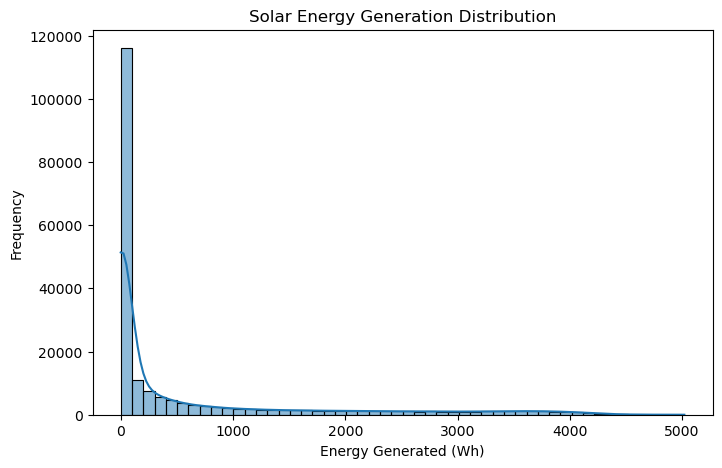

In [10]:
plt.figure(figsize=(8,5))

sns.histplot(df['Energy delta[Wh]'], bins=50, kde=True)

plt.title("Solar Energy Generation Distribution")
plt.xlabel("Energy Generated (Wh)")
plt.ylabel("Frequency")

plt.show()

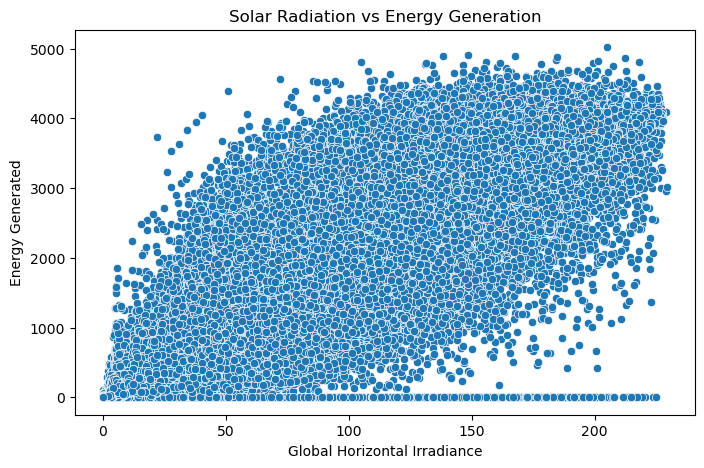

In [11]:
## Solar generation based on sunlight
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df['GHI'],
    y=df['Energy delta[Wh]']
)

plt.title("Solar Radiation vs Energy Generation")
plt.xlabel("Global Horizontal Irradiance")
plt.ylabel("Energy Generated")

plt.show()

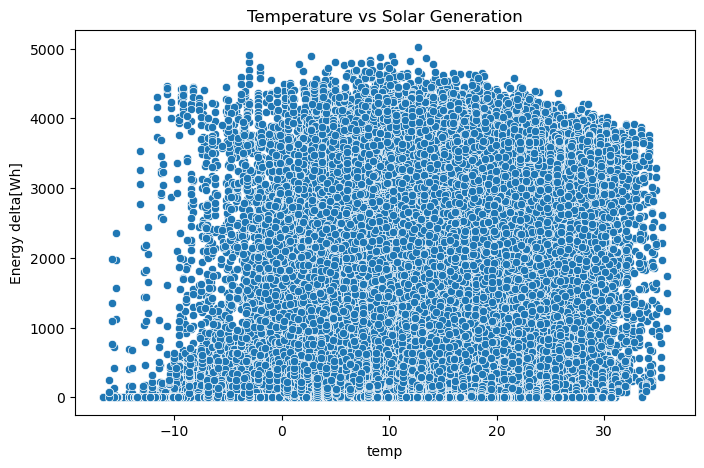

In [12]:
## Temperature vs solar generation
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df['temp'],
    y=df['Energy delta[Wh]']
)

plt.title("Temperature vs Solar Generation")

plt.show()

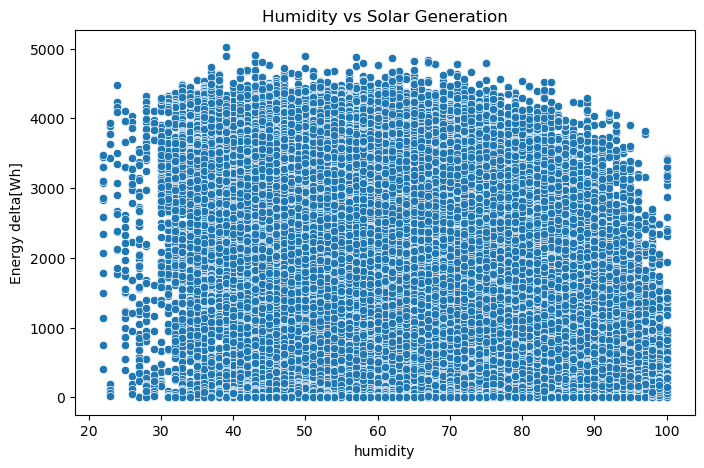

In [13]:
## Humidity vs solar generation
plt.figure(figsize=(8,5))

sns.scatterplot(
    x=df['humidity'],
    y=df['Energy delta[Wh]']
)

plt.title("Humidity vs Solar Generation")

plt.show()

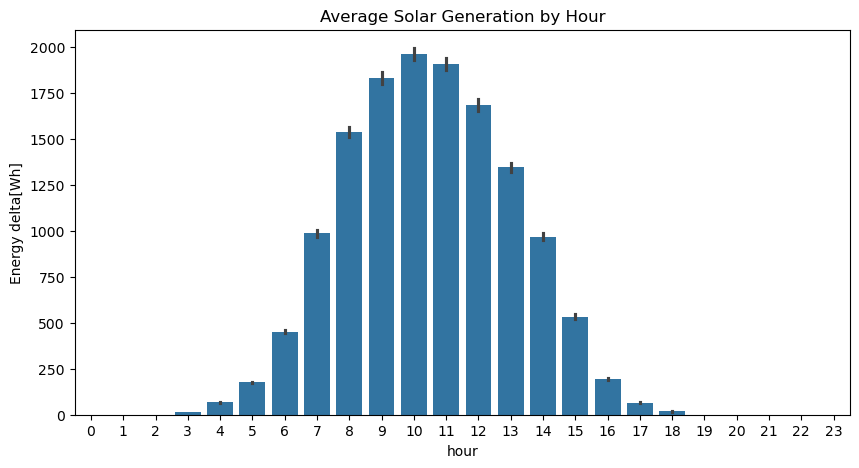

In [14]:
## Solar generation by hour
plt.figure(figsize=(10,5))

sns.barplot(
    x='hour',
    y='Energy delta[Wh]',
    data=df
)

plt.title("Average Solar Generation by Hour")
plt.show()

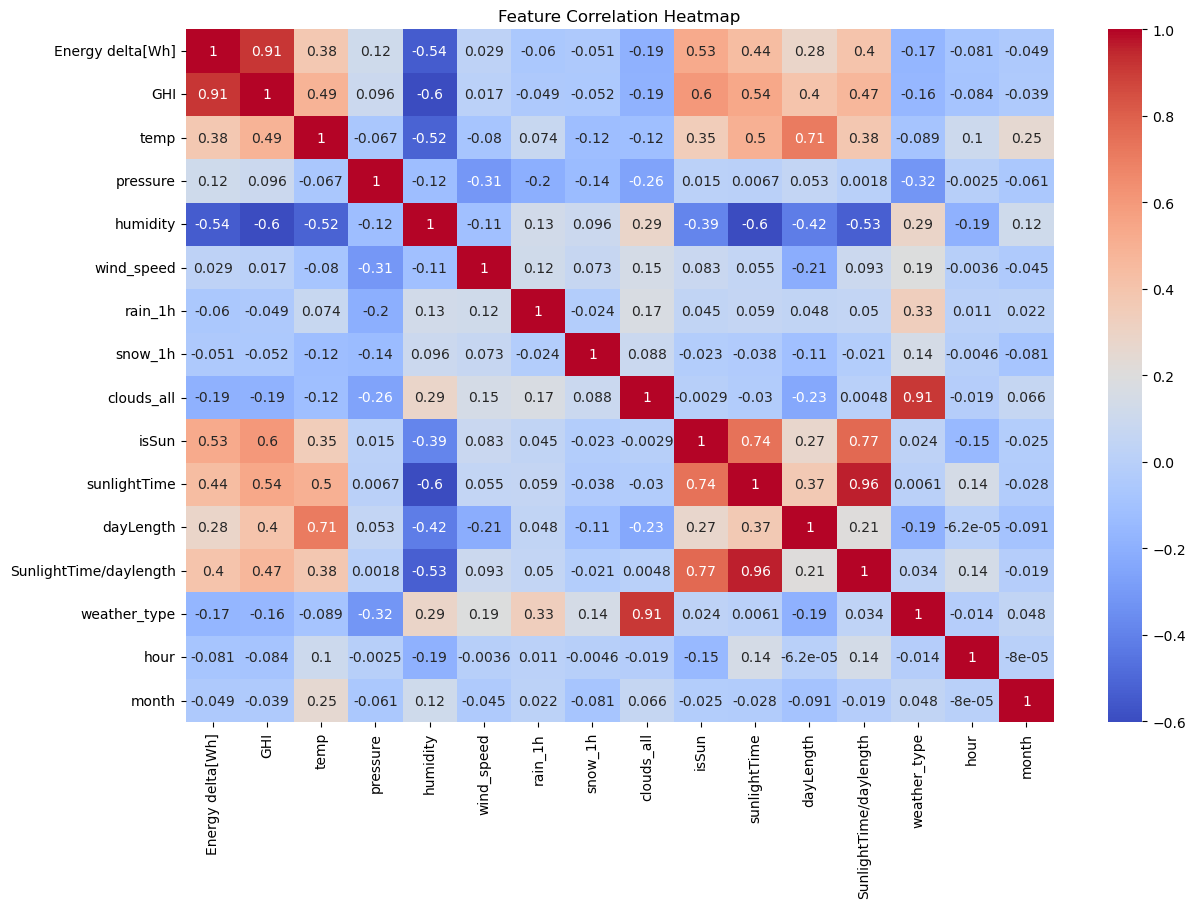

In [15]:
## Correlation heatmap
plt.figure(figsize=(14,9))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [16]:
## Check missing values
df.isnull().sum()

Time                      0
Energy delta[Wh]          0
GHI                       0
temp                      0
pressure                  0
humidity                  0
wind_speed                0
rain_1h                   0
snow_1h                   0
clouds_all                0
isSun                     0
sunlightTime              0
dayLength                 0
SunlightTime/daylength    0
weather_type              0
hour                      0
month                     0
dtype: int64

In [17]:
## Check missing value percentage
(df.isnull().sum() / len(df)) * 100

Time                      0.0
Energy delta[Wh]          0.0
GHI                       0.0
temp                      0.0
pressure                  0.0
humidity                  0.0
wind_speed                0.0
rain_1h                   0.0
snow_1h                   0.0
clouds_all                0.0
isSun                     0.0
sunlightTime              0.0
dayLength                 0.0
SunlightTime/daylength    0.0
weather_type              0.0
hour                      0.0
month                     0.0
dtype: float64

In [18]:
## Handle missing values
df['Energy delta[Wh]'] = pd.to_numeric(
    df['Energy delta[Wh]'], errors='coerce'
)

df = df.dropna(subset=['Energy delta[Wh]'])

In [19]:
## Check duplicates
df.duplicated().sum()

np.int64(0)

In [20]:
## Remove duplicates
df.drop_duplicates(inplace=True)

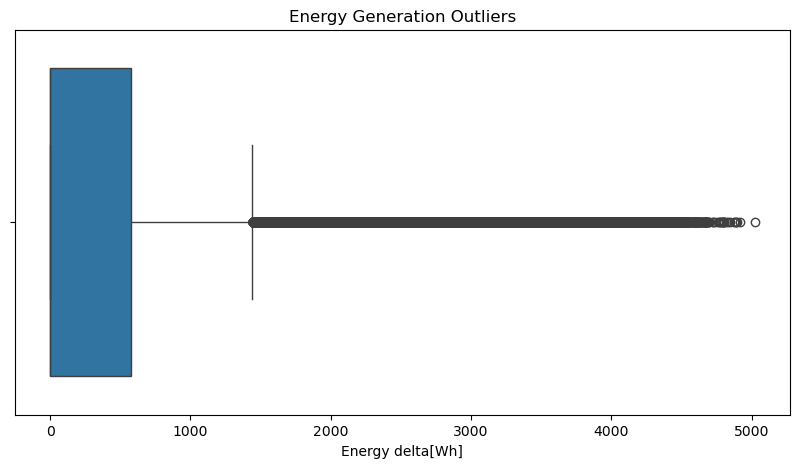

In [21]:
## Detect outliers using a boxplot
plt.figure(figsize=(10,5))

sns.boxplot(x=df['Energy delta[Wh]'])

plt.title("Energy Generation Outliers")
plt.show()

In [22]:
## Calculate IQR
Q1 = df['Energy delta[Wh]'].quantile(0.25)

Q3 = df['Energy delta[Wh]'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Lower limit: -865.5
Upper limit: 1442.5


In [23]:
## Count outliers
outliers = df[
    (df['Energy delta[Wh]'] < lower_limit) |
    (df['Energy delta[Wh]'] > upper_limit)
]

print("Number of outliers:", len(outliers))

Number of outliers: 30881


## Feature engineering
Feature engineering means creating useful new features from existing features.

Your dataset already contains hour and month. We can create cyclical features because hours and months are circular.

For example, hour 23 is close to hour 0, not far away from it.

In [24]:
# Hour cyclical features

df['hour_sin'] = np.sin(
    2 * np.pi * df['hour'] / 24
)

df['hour_cos'] = np.cos(
    2 * np.pi * df['hour'] / 24
)

In [25]:
## Create month cyclical features:
df['month_sin'] = np.sin(
    2 * np.pi * df['month'] / 12
)

df['month_cos'] = np.cos(
    2 * np.pi * df['month'] / 12
)

In [26]:
## Convert Time into datetime:
df['Time'] = pd.to_datetime(df['Time'])

df = df.sort_values('Time').reset_index(drop=True)

## Separate independent and dependent variables

In [27]:
X = df.drop(
    columns=['Energy delta[Wh]', 'Time']
)

y = df['Energy delta[Wh]']

In [28]:
## Check independent variables:
X.head()

,GHI,temp,pressure,humidity,wind_speed,rain_1h,snow_1h,clouds_all,isSun,sunlightTime,dayLength,SunlightTime/daylength,weather_type,hour,month,hour_sin,hour_cos,month_sin,month_cos
0,0.0,1.6,1021,100,4.9,0.0,0.0,100,0,0,450,0.0,4,0,1,0.000000,1.000000,0.5,0.866025
1,0.0,1.6,1021,100,4.9,0.0,0.0,100,0,0,450,0.0,4,0,1,0.000000,1.000000,0.5,0.866025
2,0.0,1.6,1021,100,4.9,0.0,0.0,100,0,0,450,0.0,4,0,1,0.000000,1.000000,0.5,0.866025
3,0.0,1.6,1021,100,4.9,0.0,0.0,100,0,0,450,0.0,4,0,1,0.000000,1.000000,0.5,0.866025
4,0.0,1.7,1020,100,5.2,0.0,0.0,100,0,0,450,0.0,4,1,1,0.258819,0.965926,0.5,0.866025


In [29]:
## Check dependent variable:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: Energy delta[Wh], dtype: int64

In [31]:
## Check shapes:
print("X shape:", X.shape)

print("y shape:", y.shape)
## Your dataset now has 16 input features, including the four newly engineered cyclical features.

X shape: (196776, 19)
y shape: (196776,)


## Encode categorical variables
The weather_type column represents weather categories. Although it is stored as an integer, we should treat it as categorical rather than assuming that weather category 4 is numerically greater than category 1.

We will use One-Hot Encoding.

In [32]:
categorical_columns = ['weather_type']

numerical_columns = [
    col for col in X.columns
    if col not in categorical_columns
]

In [33]:
## Create a preprocessing pipeline:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [34]:
## Combine both transformations:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

## Split data into training and testing sets

In [35]:
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]

X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]

y_test = y.iloc[split_index:]

In [36]:
print("X_train:", X_train.shape)

print("X_test:", X_test.shape)

print("y_train:", y_train.shape)

print("y_test:", y_test.shape)

X_train: (157420, 19)
X_test: (39356, 19)
y_train: (157420,)
y_test: (39356,)


## Build Machine Learning models
We will compare four traditional regression algorithms.
1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor

In [37]:
models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=15,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        n_jobs=-1,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

## Train all models

In [38]:
results = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('model', model)
        ]
    )

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Evaluate
    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

    trained_models[name] = pipeline

    print("\nModel:", name)

    print("MAE:", mae)

    print("MSE:", mse)

    print("RMSE:", rmse)

    print("R2 Score:", r2)


Model: Linear Regression
MAE: 242.4915846232549
MSE: 184094.63741124567
RMSE: 429.0625099111383
R2 Score: 0.8319188930997514

Model: Decision Tree
MAE: 154.5415785969171
MSE: 147988.70153604625
RMSE: 384.6929964738717
R2 Score: 0.8648841426741651

Model: Random Forest
MAE: 129.7594319712439
MSE: 106116.00897474788
RMSE: 325.7545225699067
R2 Score: 0.9031145257725862

Model: Gradient Boosting
MAE: 146.19270230246948
MSE: 111294.08363673426
RMSE: 333.60767922326704
R2 Score: 0.8983868675798352


## Compare model performance

In [39]:
results_df = pd.DataFrame(results)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,242.491585,184094.637411,429.062510,0.831919
1,Decision Tree,154.541579,147988.701536,384.692996,0.864884
2,Random Forest,129.759432,106116.008975,325.754523,0.903115
3,Gradient Boosting,146.192702,111294.083637,333.607679,0.898387


In [40]:
results_df = results_df.sort_values(
    by='RMSE',
    ascending=True
)

results_df

,Model,MAE,MSE,RMSE,R2 Score
2,Random Forest,129.759432,106116.008975,325.754523,0.903115
3,Gradient Boosting,146.192702,111294.083637,333.607679,0.898387
1,Decision Tree,154.541579,147988.701536,384.692996,0.864884
0,Linear Regression,242.491585,184094.637411,429.062510,0.831919


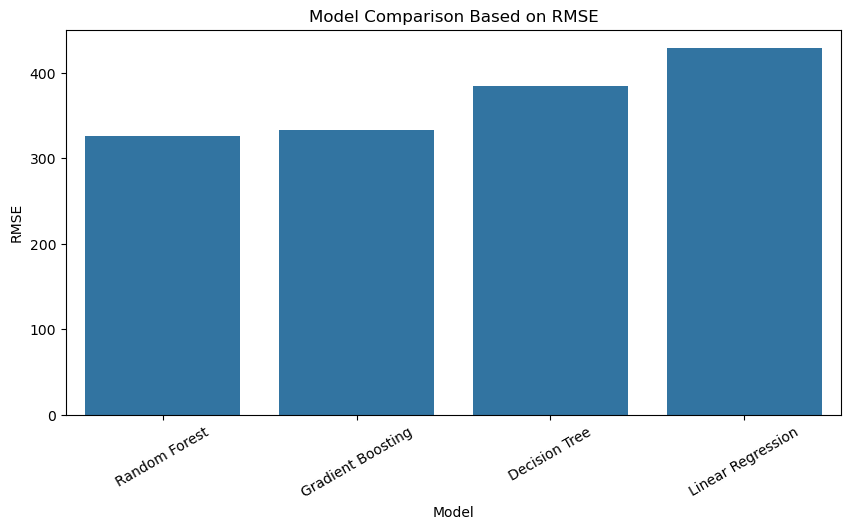

In [41]:
## Visualize model comparison:
plt.figure(figsize=(10,5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title("Model Comparison Based on RMSE")

plt.xticks(rotation=30)

plt.show()

In [42]:
## Actual vs predicted values
## Choose the model with the lowest RMSE
best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

Best model: Random Forest


In [43]:
y_pred = best_model.predict(X_test)

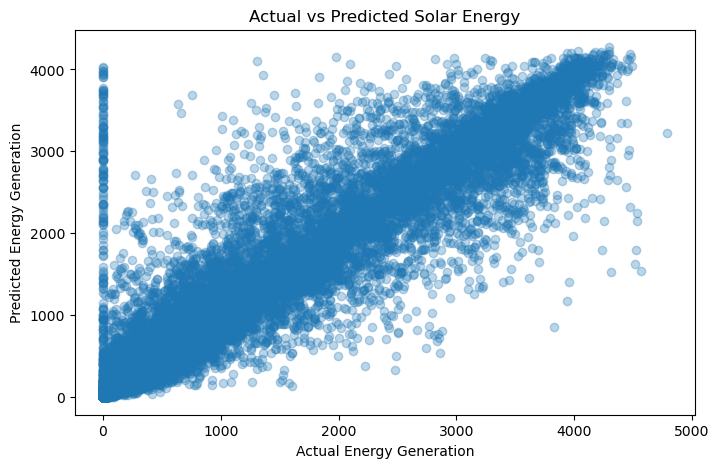

In [44]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual Energy Generation")

plt.ylabel("Predicted Energy Generation")

plt.title("Actual vs Predicted Solar Energy")

plt.show()

## Hyperparameter tuning

In [45]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import TimeSeriesSplit

rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),

        ('model', RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [46]:
## Define hyperparameters
param_grid = {
    'model__n_estimators': [50, 100, 150],

    'model__max_depth': [10, 15, 20, None],

    'model__min_samples_split': [2, 5, 10],

    'model__min_samples_leaf': [1, 2, 4]
}

In [47]:
## Create time-series cross-validation
tscv = TimeSeriesSplit(n_splits=3)

In [48]:
## To reduce computation time, use the latest 40,000 training records for tuning.
tune_size = min(40000, len(X_train))

X_tune = X_train.iloc[-tune_size:]

y_tune = y_train.iloc[-tune_size:]

In [49]:
## Create RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,

    param_distributions=param_grid,

    n_iter=5,

    cv=tscv,

    scoring='neg_root_mean_squared_error',

    random_state=42,

    n_jobs=-1,

    verbose=1
)

In [50]:
random_search.fit(X_tune, y_tune)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__max_depth': [10, 15, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], 'model__n_estimators': [50, 100, ...]}"
,n_iter,5
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [51]:
print(random_search.best_params_)

{'model__n_estimators': 150, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_depth': 20}


In [52]:
print(random_search.best_score_)

-346.5957713482704


In [53]:
tuned_model = random_search.best_estimator_

tuned_pred = tuned_model.predict(X_test)

print("Tuned MAE:",
      mean_absolute_error(y_test, tuned_pred))

print("Tuned RMSE:",
      np.sqrt(mean_squared_error(y_test, tuned_pred)))

print("Tuned R2:",
      r2_score(y_test, tuned_pred))

Tuned MAE: 138.52865023489036
Tuned RMSE: 341.0492484217626
Tuned R2: 0.893803071695111


In [54]:
## Compare the tuned Random Forest with the original models:
print("Original best RMSE:",
      results_df.iloc[0]['RMSE'])

print("Tuned Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_test, tuned_pred)))

Original best RMSE: 325.7545225699067
Tuned Random Forest RMSE: 341.0492484217626


In [55]:
## save the model
original_best_rmse = results_df.iloc[0]['RMSE']

tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_pred)
)

if tuned_rmse < original_best_rmse:
    final_model = tuned_model
    final_model_name = "Tuned Random Forest"
else:
    final_model = best_model
    final_model_name = best_model_name

print("Final model:", final_model_name)

Final model: Random Forest


In [56]:
import joblib

joblib.dump(
    final_model,
    "solar_power_model.pkl"
)

['solar_power_model.pkl']

In [57]:
loaded_model = joblib.load(
    "solar_power_model.pkl"
)

In [58]:
sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)

print("Predicted Energy:", prediction[0])

print("Actual Energy:", y_test.iloc[0])

Predicted Energy: 22.65950397788786
Actual Energy: 35


In [59]:
import sklearn

print(sklearn.__version__)

1.7.2
